in this notebook, we look at the outliers (studentized residuals beyond +/- 3) and compare the actual daily returns of spy with the returns predicted by our ols model.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# import the csv into dataframe
data1 = pd.read_csv("../../data/Données SPY.csv")
data2 = pd.read_csv("../../data/AAPL.csv")
data3 = pd.read_csv("../../data/USD_CNY.csv")
data4 = pd.read_csv("../../data/DTB6.csv")
data5 = pd.read_csv("../../data/HIS.csv")
data6 = pd.read_csv("../../data/Gold.csv")
data7 = pd.read_csv("../../data/TCD6.csv")
data8 = pd.read_csv("../../data/DR5.xls")
data9 = pd.read_csv("../../data/Taux_ST6.xls")
data10 = pd.read_csv("../../data/VRV.xls")

# standardize columns and convert date
for df in [data1, data2, data3, data4, data5, data6, data7, data8, data9, data10]:
    df.columns = [col.strip().capitalize() for col in df.columns]
    if 'Unnamed: 0' in df.columns:
        df.rename(columns={'Unnamed: 0':'Date'}, inplace=True)
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# compute returns before merging
# specific cleaning for the his file
data5['Price'] = data5['Price'].astype(str)
data5['Price'] = data5['Price'].str.replace(',', '', regex=False)  # remove commas
data5['Price'] = pd.to_numeric(data5['Price'], errors='coerce')

col_names = ['SPY','AAPL','DollarYuan','DTB6','HIS','Or','DCD6M', 'DR5', 'Taux_ST6', 'VRV']
col_prices = ['Price','Price','Price','Dtb6','Price','Price','Dcd6m','Price', 'Price', 'Price']
dataframes = [data1, data2, data3, data4, data5, data6, data7, data8, data9, data10]

for df, name, price in zip(dataframes, col_names, col_prices):
    if price in df.columns:
        # convert column to numeric before calculation
        df[price] = pd.to_numeric(df[price], errors='coerce')
        # compute daily return in proportion
        df[name] = df[price].pct_change()
        # drop first nan rows
        df.dropna(subset=[name], inplace=True)

# merge files on date column with outer join
# start from spy already converted to return
data_merged = data1[['Date','SPY']]

# list of remaining files to merge
dfs = [data2, data3, data4, data5, data6, data7, data8, data9, data10]
col_names = ['AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV' ]
col_prices = ['AAPL','DollarYuan','DTB6','Price','Or','DCD6M','Dr5', 'St6', 'Vrv']  # merge on already computed returns

for df, col_name, price_col in zip(dfs, col_names, col_prices):
    data_merged = data_merged.merge(df[['Date', price_col]], on='Date', how='outer')
    data_merged.rename(columns={price_col: col_name}, inplace=True)

# fill missing values
data_merged.ffill(inplace=True)
data_merged.bfill(inplace=True)
for col in ['SPY','AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV' ]:
    data_merged[col] = pd.to_numeric(data_merged[col], errors='coerce')
    if data_merged[col].isna().sum() > 0:
        data_merged[col] = data_merged[col].fillna(data_merged[col].mean())

# drop columns with more than 50% nan
X_multi = data_merged[['AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV']]
X_multi = X_multi.loc[:, X_multi.isna().mean() < 0.5]
y = data_merged[['SPY']]

# final cleaning: drop remaining rows with nan
data_clean = pd.concat([X_multi, y], axis=1).dropna()
X_multi = data_clean.drop(columns=['SPY'])
y = data_clean[['SPY']]

# fit multiple ols regression model
X_multi_sm = sm.add_constant(X_multi)
mon_modele = sm.OLS(y, X_multi_sm).fit()

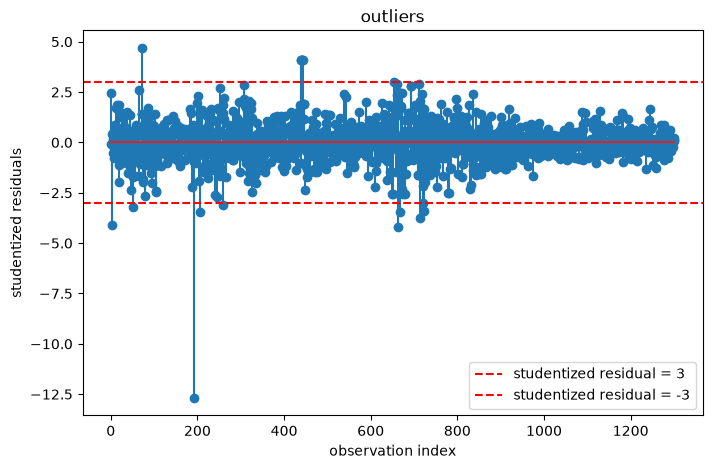

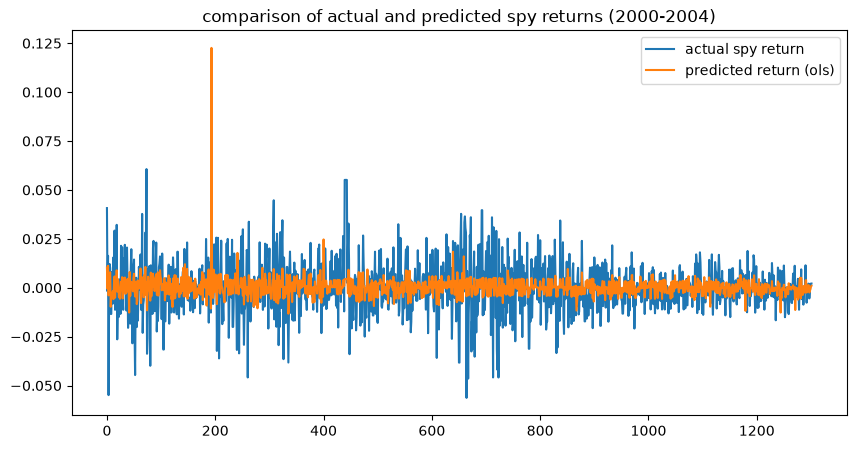

In [2]:
# outlier analysis
# influence and studentized residuals
influence = mon_modele.get_influence()
summary_frame = influence.summary_frame()
resid_studentise = influence.resid_studentized_external

# detect outliers
outliers = resid_studentise[abs(resid_studentise) > 3]

# plot
plt.figure(figsize=(8,5))
plt.stem(resid_studentise)
plt.axhline(y=3, color='red', linestyle='--', label='studentized residual = 3')
plt.axhline(y=-3, color='red', linestyle='--', label='studentized residual = -3')
plt.xlabel("observation index")
plt.ylabel("studentized residuals")
plt.title("outliers")
plt.legend()
plt.show()

# points beyond the red lines are considered outliers
# they can indicate data entry errors, extreme market days, or special events
# it is recommended to inspect them before deciding to remove them

y_pred = mon_modele.predict(X_multi_sm)

plt.figure(figsize=(10,5))
plt.plot(y.values, label="actual spy return")
plt.plot(y_pred.values, label="predicted return (ols)")
plt.title("comparison of actual and predicted spy returns (2000-2004)")
plt.legend()
plt.show()

a few observations cross the +/- 3 threshold, which correspond to days of high market volatility between 2000 and 2004. on the second chart, we see that our ols prediction follows the general direction of spy returns, but underestimates the big daily spikes.